In [2]:
# Импорт необходимых библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(2024)

# Настройка отображения графиков
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

генерация данных

In [4]:
#количество заказов нужно сделать 3к
n_orders = 3000

cities = ["Москва", "Санкт-Петербург", "Казань", "Екатеринбург", "Челябинск"]
categories = ["Электроника", "Одежда", "Дом", "Красота", "Спорт"]
statuses = ["Доставлен", "Отменён", "Возврат"]
payments = ["Карта", "Онлайн", "Наличные"]

products = {
    "Электроника": ["Смартфон", "Ноутбук", "Наушники", "Планшет", "Телевизор"],
    "Одежда": ["Футболка", "Джинсы", "Куртка", "Платье", "Свитер"],
    "Дом": ["Пылесос", "Чайник", "Микроволновка", "Диван", "Лампа"],
    "Красота": ["Крем", "Шампунь", "Парфюм", "Помада", "Маска"],
    "Спорт": ["Гантели", "Кроссовки", "Коврик", "Велосипед", "Скакалка"]
}

#генерация данных
order_ids = np.arange(1, n_orders + 1)
order_dates = pd.date_range(start="2023-01-01", end="2024-12-31", periods=n_orders)
customer_ids = np.random.randint(1, 800, size=n_orders)
city_col = np.random.choice(cities, size=n_orders)
age_col = np.random.randint(16, 75, size=n_orders).astype(float)
is_vip_col = np.random.choice([True, False], size=n_orders, p=[0.2, 0.8])

category_col = np.random.choice(categories, size=n_orders)
product_col = [np.random.choice(products[cat]) for cat in category_col]
quantity_col = np.random.randint(1, 6, size=n_orders)
price_col = np.random.randint(300, 20000, size=n_orders)
discount_col = np.round(np.random.uniform(0, 0.4, size=n_orders), 2)
cost_col = np.round(price_col * np.random.uniform(0.4, 0.9, size=n_orders), 2)
status_col = np.random.choice(statuses, size=n_orders, p=[0.8, 0.1, 0.1])
payment_col = np.random.choice(payments, size=n_orders)

In [5]:
# Создание DataFrame
df = pd.DataFrame({
    "order_id": order_ids,
    "order_date": order_dates,
    "customer_id": customer_ids,
    "city": city_col,
    "age": age_col,
    "is_vip": is_vip_col,
    "product_name": product_col,
    "category": category_col,
    "quantity": quantity_col,
    "price": price_col,
    "discount": discount_col,
    "cost": cost_col,
    "status": status_col,
    "payment": payment_col
})

In [6]:
# Добавление 30 пропусков в age
missing_idx = np.random.choice(df.index, size=30, replace=False)
df.loc[missing_idx, "age"] = np.nan

print("DataFrame создан. Размер:", df.shape)
df.head()

DataFrame создан. Размер: (3000, 14)


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,1,2023-01-01 00:00:00.000000000,45,Санкт-Петербург,41.0,False,Коврик,Спорт,5,1567,0.14,711.49,Доставлен,Наличные
1,2,2023-01-01 05:50:31.010336778,638,Казань,51.0,False,Футболка,Одежда,5,2510,0.32,2119.99,Доставлен,Карта
2,3,2023-01-01 11:41:02.020673557,797,Москва,65.0,False,Микроволновка,Дом,5,2002,0.31,1599.16,Доставлен,Карта
3,4,2023-01-01 17:31:33.031010336,448,Казань,69.0,False,Ноутбук,Электроника,5,10088,0.23,4970.11,Доставлен,Карта
4,5,2023-01-01 23:22:04.041347115,590,Москва,22.0,False,Лампа,Дом,5,6174,0.09,2671.10,Доставлен,Наличные


In [7]:
# Размер DataFrame
print("Размер (строки, столбцы):", df.shape)
print()

# Информация о типах и пропусках
df.info()

Размер (строки, столбцы): (3000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      3000 non-null   int64         
 1   order_date    3000 non-null   datetime64[ns]
 2   customer_id   3000 non-null   int64         
 3   city          3000 non-null   object        
 4   age           2970 non-null   float64       
 5   is_vip        3000 non-null   bool          
 6   product_name  3000 non-null   object        
 7   category      3000 non-null   object        
 8   quantity      3000 non-null   int64         
 9   price         3000 non-null   int64         
 10  discount      3000 non-null   float64       
 11  cost          3000 non-null   float64       
 12  status        3000 non-null   object        
 13  payment       3000 non-null   object        
dtypes: bool(1), datetime64[ns](1), float64(3), int64(4

In [9]:
# Первые 5 строк
df.head()


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,1,2023-01-01 00:00:00.000000000,45,Санкт-Петербург,41.0,False,Коврик,Спорт,5,1567,0.14,711.49,Доставлен,Наличные
1,2,2023-01-01 05:50:31.010336778,638,Казань,51.0,False,Футболка,Одежда,5,2510,0.32,2119.99,Доставлен,Карта
2,3,2023-01-01 11:41:02.020673557,797,Москва,65.0,False,Микроволновка,Дом,5,2002,0.31,1599.16,Доставлен,Карта
3,4,2023-01-01 17:31:33.031010336,448,Казань,69.0,False,Ноутбук,Электроника,5,10088,0.23,4970.11,Доставлен,Карта
4,5,2023-01-01 23:22:04.041347115,590,Москва,22.0,False,Лампа,Дом,5,6174,0.09,2671.10,Доставлен,Наличные


In [10]:
# Последние 5 строк
df.tail()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
2995,2996,2024-12-30 00:37:55.958652880,685,Челябинск,22.0,False,Футболка,Одежда,3,7341,0.35,5797.01,Доставлен,Онлайн
2996,2997,2024-12-30 06:28:26.968989664,402,Екатеринбург,39.0,False,Куртка,Одежда,1,3562,0.17,2299.60,Доставлен,Онлайн
2997,2998,2024-12-30 12:18:57.979326440,11,Санкт-Петербург,42.0,False,Коврик,Спорт,5,16329,0.31,7293.40,Доставлен,Онлайн
2998,2999,2024-12-30 18:09:28.989663216,537,Санкт-Петербург,55.0,False,Диван,Дом,3,9427,0.03,7819.82,Доставлен,Наличные
2999,3000,2024-12-31 00:00:00.000000000,506,Казань,57.0,False,Лампа,Дом,1,17981,0.05,11995.95,Доставлен,Карта


In [11]:
# Статистика по числовым столбцам
df.describe()

,order_id,order_date,customer_id,age,quantity,price,discount,cost
count,3000.000000,3000,3000.000000,2970.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,2023-12-31 23:59:59.999999488,394.133000,45.127273,2.961667,9948.953000,0.199517,6468.058107
min,1.000000,2023-01-01 00:00:00,1.000000,16.000000,1.000000,302.000000,0.000000,157.850000
25%,750.750000,2023-07-02 12:00:00,197.000000,30.000000,2.000000,5113.500000,0.100000,3099.892500
50%,1500.500000,2024-01-01 00:00:00,389.500000,45.000000,3.000000,9859.000000,0.200000,6005.700000
75%,2250.250000,2024-07-01 12:00:00,590.000000,60.000000,4.000000,14741.000000,0.300000,9230.405000
max,3000.000000,2024-12-31 00:00:00,799.000000,74.000000,5.000000,19986.000000,0.400000,17646.720000
std,866.169729,NaN,229.013771,17.186375,1.425555,5657.951301,0.116471,4054.188343


In [12]:
# Количество пропусков по столбцам
df.isna().sum()

,0
order_id,0
order_date,0
customer_id,0
city,0
age,30
is_vip,0
product_name,0
category,0
quantity,0
price,0


In [16]:
#ответы на вопросы
print("1. Строк и столбцов:", df.shape)
print("2. Столбцы с пропусками:")
print(df.columns[df.isna().any()].tolist())
print("3. Пропусков в age:", df["age"].isna().sum())
print("4. Уникальных клиентов:", df["customer_id"].nunique())
print("5. Уникальных товаров:", df["product_name"].nunique())
print("6. Города:", df["city"].unique().tolist())
print("7. Категории:", df["category"].unique().tolist())
print("8. Способы оплаты:", df["payment"].unique().tolist())

1. Строк и столбцов: (3000, 14)
2. Столбцы с пропусками:
['age']
3. Пропусков в age: 30
4. Уникальных клиентов: 777
5. Уникальных товаров: 25
6. Города: ['Санкт-Петербург', 'Казань', 'Москва', 'Челябинск', 'Екатеринбург']
7. Категории: ['Спорт', 'Одежда', 'Дом', 'Электроника', 'Красота']
8. Способы оплаты: ['Наличные', 'Карта', 'Онлайн']


Подготовка данных

In [17]:
#работа с датой

# Преобразование order_date в тип даты
df["order_date"] = pd.to_datetime(df["order_date"])

# Создание столбцов year и month
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month

df[["order_date", "year", "month"]].head()

,order_date,year,month
0,2023-01-01 00:00:00.000000000,2023,1
1,2023-01-01 05:50:31.010336778,2023,1
2,2023-01-01 11:41:02.020673557,2023,1
3,2023-01-01 17:31:33.031010336,2023,1
4,2023-01-01 23:22:04.041347115,2023,1


In [18]:
  # Выручка с учётом скидки
df["revenue"] = df["price"] * df["quantity"] * (1 - df["discount"])

# Прибыль
df["profit"] = df["revenue"] - df["cost"]

df[["price", "quantity", "discount", "revenue", "cost", "profit"]].head()

,price,quantity,discount,revenue,cost,profit
0,1567,5,0.14,6738.1,711.49,6026.61
1,2510,5,0.32,8534.0,2119.99,6414.01
2,2002,5,0.31,6906.9,1599.16,5307.74
3,10088,5,0.23,38838.8,4970.11,33868.69
4,6174,5,0.09,28091.7,2671.10,25420.60


In [19]:
# Признак реальной продажи
df["is_real_sale"] = df["status"] == "Доставлен"

df["is_real_sale"].value_counts()

,count
is_real_sale,
True,2423
False,577


In [20]:
# Медианный возраст
median_age = df["age"].median()
print("Медианный возраст:", median_age)

# Заполнение пропусков медианой
df["age"] = df["age"].fillna(median_age)

# Проверка
print("Пропусков в age после заполнения:", df["age"].isna().sum())

Медианный возраст: 45.0
Пропусков в age после заполнения: 0


In [23]:
bins = [0, 18, 30, 45, 60, 100]
labels = [
 "до 18",
 "18–30",
 "31–45",
 "46–60",
 "60+"
]
df["age_group"] = pd.cut(
 df["age"],
 bins=bins,
 labels=labels
)

df["age_group"].value_counts().sort_index()

,count
age_group,
до 18,157
18–30,599
31–45,780
46–60,747
60+,717


In [24]:
#фильтрация
df[df["quantity"] > 3].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
0,1,2023-01-01 00:00:00.000000000,45,Санкт-Петербург,41.0,False,Коврик,Спорт,5,1567,0.14,711.49,Доставлен,Наличные,2023,1,6738.1,6026.61,True,31–45
1,2,2023-01-01 05:50:31.010336778,638,Казань,51.0,False,Футболка,Одежда,5,2510,0.32,2119.99,Доставлен,Карта,2023,1,8534.0,6414.01,True,46–60
2,3,2023-01-01 11:41:02.020673557,797,Москва,65.0,False,Микроволновка,Дом,5,2002,0.31,1599.16,Доставлен,Карта,2023,1,6906.9,5307.74,True,60+
3,4,2023-01-01 17:31:33.031010336,448,Казань,69.0,False,Ноутбук,Электроника,5,10088,0.23,4970.11,Доставлен,Карта,2023,1,38838.8,33868.69,True,60+
4,5,2023-01-01 23:22:04.041347115,590,Москва,22.0,False,Лампа,Дом,5,6174,0.09,2671.10,Доставлен,Наличные,2023,1,28091.7,25420.60,True,18–30


In [25]:
df[df["city"] == "Москва"].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
2,3,2023-01-01 11:41:02.020673557,797,Москва,65.0,False,Микроволновка,Дом,5,2002,0.31,1599.16,Доставлен,Карта,2023,1,6906.9,5307.74,True,60+
4,5,2023-01-01 23:22:04.041347115,590,Москва,22.0,False,Лампа,Дом,5,6174,0.09,2671.10,Доставлен,Наличные,2023,1,28091.7,25420.60,True,18–30
9,10,2023-01-03 04:34:39.093031010,622,Москва,73.0,False,Крем,Красота,4,15991,0.30,13844.72,Доставлен,Карта,2023,1,44774.8,30930.08,True,60+
10,11,2023-01-03 10:25:10.103367789,566,Москва,40.0,False,Ноутбук,Электроника,2,11385,0.34,4843.08,Отменён,Карта,2023,1,15028.2,10185.12,False,31–45
11,12,2023-01-03 16:15:41.113704568,30,Москва,39.0,True,Кроссовки,Спорт,5,4720,0.09,3430.08,Доставлен,Наличные,2023,1,21476.0,18045.92,True,31–45


In [26]:
df[df["is_vip"]].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
7,8,2023-01-02 16:53:37.072357452,213,Челябинск,33.0,True,Чайник,Дом,3,8176,0.14,4125.85,Доставлен,Наличные,2023,1,21094.08,16968.23,True,31–45
11,12,2023-01-03 16:15:41.113704568,30,Москва,39.0,True,Кроссовки,Спорт,5,4720,0.09,3430.08,Доставлен,Наличные,2023,1,21476.00,18045.92,True,31–45
12,13,2023-01-03 22:06:12.124041347,701,Санкт-Петербург,27.0,True,Маска,Красота,4,5014,0.25,2710.61,Доставлен,Онлайн,2023,1,15042.00,12331.39,True,18–30
27,28,2023-01-07 13:43:57.279093031,306,Москва,27.0,True,Диван,Дом,5,11272,0.19,9095.69,Доставлен,Наличные,2023,1,45651.60,36555.91,True,18–30
32,33,2023-01-08 18:56:32.330776925,764,Екатеринбург,20.0,True,Кроссовки,Спорт,4,14954,0.18,8544.99,Доставлен,Онлайн,2023,1,49049.12,40504.13,True,18–30


In [27]:
df[df["price"] > 5000].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
3,4,2023-01-01 17:31:33.031010336,448,Казань,69.0,False,Ноутбук,Электроника,5,10088,0.23,4970.11,Доставлен,Карта,2023,1,38838.80,33868.69,True,60+
4,5,2023-01-01 23:22:04.041347115,590,Москва,22.0,False,Лампа,Дом,5,6174,0.09,2671.10,Доставлен,Наличные,2023,1,28091.70,25420.60,True,18–30
5,6,2023-01-02 05:12:35.051683894,386,Казань,45.0,False,Микроволновка,Дом,4,9020,0.04,5713.68,Возврат,Карта,2023,1,34636.80,28923.12,False,31–45
7,8,2023-01-02 16:53:37.072357452,213,Челябинск,33.0,True,Чайник,Дом,3,8176,0.14,4125.85,Доставлен,Наличные,2023,1,21094.08,16968.23,True,31–45
9,10,2023-01-03 04:34:39.093031010,622,Москва,73.0,False,Крем,Красота,4,15991,0.30,13844.72,Доставлен,Карта,2023,1,44774.80,30930.08,True,60+


In [28]:
df[df["discount"] > 0.2].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2023-01-01 05:50:31.010336778,638,Казань,51.0,False,Футболка,Одежда,5,2510,0.32,2119.99,Доставлен,Карта,2023,1,8534.0,6414.01,True,46–60
2,3,2023-01-01 11:41:02.020673557,797,Москва,65.0,False,Микроволновка,Дом,5,2002,0.31,1599.16,Доставлен,Карта,2023,1,6906.9,5307.74,True,60+
3,4,2023-01-01 17:31:33.031010336,448,Казань,69.0,False,Ноутбук,Электроника,5,10088,0.23,4970.11,Доставлен,Карта,2023,1,38838.8,33868.69,True,60+
9,10,2023-01-03 04:34:39.093031010,622,Москва,73.0,False,Крем,Красота,4,15991,0.30,13844.72,Доставлен,Карта,2023,1,44774.8,30930.08,True,60+
10,11,2023-01-03 10:25:10.103367789,566,Москва,40.0,False,Ноутбук,Электроника,2,11385,0.34,4843.08,Отменён,Карта,2023,1,15028.2,10185.12,False,31–45


In [29]:
df["status"].value_counts()

,count
status,
Доставлен,2423
Возврат,289
Отменён,288


In [30]:
df[(df["city"] == "Москва") & (df["revenue"] > 5000)].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
2,3,2023-01-01 11:41:02.020673557,797,Москва,65.0,False,Микроволновка,Дом,5,2002,0.31,1599.16,Доставлен,Карта,2023,1,6906.9,5307.74,True,60+
4,5,2023-01-01 23:22:04.041347115,590,Москва,22.0,False,Лампа,Дом,5,6174,0.09,2671.10,Доставлен,Наличные,2023,1,28091.7,25420.60,True,18–30
9,10,2023-01-03 04:34:39.093031010,622,Москва,73.0,False,Крем,Красота,4,15991,0.30,13844.72,Доставлен,Карта,2023,1,44774.8,30930.08,True,60+
10,11,2023-01-03 10:25:10.103367789,566,Москва,40.0,False,Ноутбук,Электроника,2,11385,0.34,4843.08,Отменён,Карта,2023,1,15028.2,10185.12,False,31–45
11,12,2023-01-03 16:15:41.113704568,30,Москва,39.0,True,Кроссовки,Спорт,5,4720,0.09,3430.08,Доставлен,Наличные,2023,1,21476.0,18045.92,True,31–45


In [31]:
df[(df["is_vip"]) & (df["category"] == "Электроника")].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
36,37,2023-01-09 18:18:36.372124041,667,Челябинск,21.0,True,Ноутбук,Электроника,4,6085,0.00,4129.03,Возврат,Карта,2023,1,24340.00,20210.97,False,18–30
38,39,2023-01-10 05:59:38.392797599,481,Санкт-Петербург,52.0,True,Ноутбук,Электроника,4,18286,0.17,16409.18,Доставлен,Онлайн,2023,1,60709.52,44300.34,True,46–60
76,77,2023-01-19 11:59:16.785595198,485,Челябинск,42.0,True,Планшет,Электроника,4,4625,0.19,2085.70,Доставлен,Онлайн,2023,1,14985.00,12899.30,True,31–45
78,79,2023-01-19 23:40:18.806268756,258,Екатеринбург,41.0,True,Ноутбук,Электроника,3,9956,0.16,7397.07,Доставлен,Онлайн,2023,1,25089.12,17692.05,True,31–45
85,86,2023-01-21 16:33:55.878626208,101,Екатеринбург,61.0,True,Наушники,Электроника,5,18425,0.06,16251.28,Доставлен,Карта,2023,1,86597.50,70346.22,True,60+


In [32]:
df[(df["status"] == "Доставлен") & (df["payment"] == "Онлайн")].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
12,13,2023-01-03 22:06:12.124041347,701,Санкт-Петербург,27.0,True,Маска,Красота,4,5014,0.25,2710.61,Доставлен,Онлайн,2023,1,15042.00,12331.39,True,18–30
15,16,2023-01-04 15:37:45.155051683,50,Москва,74.0,False,Планшет,Электроника,1,3539,0.26,1984.90,Доставлен,Онлайн,2023,1,2618.86,633.96,True,60+
19,20,2023-01-05 14:59:49.196398799,246,Санкт-Петербург,30.0,False,Микроволновка,Дом,1,8424,0.17,6943.10,Доставлен,Онлайн,2023,1,6991.92,48.82,True,18–30
32,33,2023-01-08 18:56:32.330776925,764,Екатеринбург,20.0,True,Кроссовки,Спорт,4,14954,0.18,8544.99,Доставлен,Онлайн,2023,1,49049.12,40504.13,True,18–30
37,38,2023-01-10 00:09:07.382460820,625,Челябинск,37.0,False,Ноутбук,Электроника,1,17071,0.26,11545.29,Доставлен,Онлайн,2023,1,12632.54,1087.25,True,31–45


In [33]:
df[df["year"] == 2024].head()

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1500,1501,2024-01-01 02:55:15.505168388,753,Казань,65.0,False,Футболка,Одежда,4,9111,0.31,8056.96,Возврат,Карта,2024,1,25146.36,17089.40,False,60+
1501,1502,2024-01-01 08:45:46.515505168,317,Казань,73.0,True,Чайник,Дом,3,16629,0.39,8655.87,Доставлен,Онлайн,2024,1,30431.07,21775.20,True,60+
1502,1503,2024-01-01 14:36:17.525841948,393,Екатеринбург,71.0,True,Куртка,Одежда,3,18102,0.05,15702.49,Доставлен,Карта,2024,1,51590.70,35888.21,True,60+
1503,1504,2024-01-01 20:26:48.536178724,292,Санкт-Петербург,32.0,False,Кроссовки,Спорт,5,7426,0.13,4151.96,Доставлен,Карта,2024,1,32303.10,28151.14,True,31–45
1504,1505,2024-01-02 02:17:19.546515504,632,Челябинск,44.0,False,Гантели,Спорт,3,10610,0.29,7214.31,Отменён,Наличные,2024,1,22599.30,15384.99,False,31–45


Экстремальные значения

In [34]:
#с максимальной выручкой
print("Максимальная выручка:")
print(df.loc[df["revenue"].idxmax()][["order_id", "revenue", "category"]])
print()

#с максимальной скидкой
print("Максимальная скидка:")
print(df.loc[df["discount"].idxmax()][["order_id", "discount", "category"]])
print()

#с максимальной прибылью
print("Максимальная прибыль:")
print(df.loc[df["profit"].idxmax()][["order_id", "profit", "category"]])
print()

#Самый молодой клиент
print("Самый молодой клиент:")
print(df.loc[df["age"].idxmin()][["order_id", "age", "city"]])
print()

#Самый старый клиент
print("Самый старший клиент:")
print(df.loc[df["age"].idxmax()][["order_id", "age", "city"]])

Максимальная выручка:
order_id        449
revenue     96932.1
category        Дом
Name: 448, dtype: object

Максимальная скидка:
order_id            197
discount            0.4
category    Электроника
Name: 196, dtype: object

Максимальная прибыль:
order_id         747
profit      87654.25
category     Красота
Name: 746, dtype: object

Самый молодой клиент:
order_id        56
age           16.0
city        Москва
Name: 55, dtype: object

Самый старший клиент:
order_id         7
age           74.0
city        Казань
Name: 6, dtype: object


группы данных


In [35]:
revenue_by_category = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(revenue_by_category)
print()
print("Категория с максимальной выручкой:", revenue_by_category.idxmax())

category
Электроника    14611679.30
Спорт          14446990.09
Одежда         14364620.39
Дом            14041474.19
Красота        13957646.14
Name: revenue, dtype: float64

Категория с максимальной выручкой: Электроника


In [36]:
#ср. выручка покатегориям
df.groupby("category")["revenue"].mean().sort_values(ascending=False)

,revenue
category,
Одежда,24305.618257
Дом,24251.250760
Красота,23577.104966
Спорт,23567.683670
Электроника,23378.686880


In [37]:
#кол-во заказов по категориям
df.groupby("category")["order_id"].count().sort_values(ascending=False)

,order_id
category,
Электроника,625
Спорт,613
Красота,592
Одежда,591
Дом,579


In [38]:
df.groupby("category")["discount"].mean().sort_values(ascending=False)

,discount
category,
Электроника,0.204528
Красота,0.202044
Одежда,0.197750
Дом,0.197513
Спорт,0.195563


In [39]:
df.groupby(["category", "city"])["revenue"].sum()

category     city           
Дом          Екатеринбург       3134621.44
             Казань             3045759.75
             Москва             2450832.86
             Санкт-Петербург    2538955.18
             Челябинск          2871304.96
Красота      Екатеринбург       2407516.04
             Казань             3485781.79
             Москва             2884216.63
             Санкт-Петербург    2421700.60
             Челябинск          2758431.08
Одежда       Екатеринбург       3043565.60
             Казань             2676575.72
             Москва             2742106.98
             Санкт-Петербург    3241444.40
             Челябинск          2660927.69
Спорт        Екатеринбург       2848850.16
             Казань             3123321.24
             Москва             2987124.71
             Санкт-Петербург    2439474.33
             Челябинск          3048219.65
Электроника  Екатеринбург       3131069.28
             Казань             2539243.25
             Москва             2286518.07
             Санкт-Петербург    2964164.96
             Челябинск          3690683.74
Name: revenue, dtype: float64

In [40]:
df[df["is_vip"]].groupby("city")["revenue"].mean().sort_values(ascending=False)

,revenue
city,
Екатеринбург,27276.902500
Челябинск,24297.873826
Казань,24250.376825
Москва,20959.591667
Санкт-Петербург,20335.629252


In [41]:
df.groupby(["city", "payment"])["order_id"].count()

city             payment 
Екатеринбург     Карта       226
                 Наличные    180
                 Онлайн      202
Казань           Карта       215
                 Наличные    212
                 Онлайн      194
Москва           Карта       202
                 Наличные    210
                 Онлайн      178
Санкт-Петербург  Карта       218
                 Наличные    175
                 Онлайн      187
Челябинск        Карта       203
                 Наличные    200
                 Онлайн      198
Name: order_id, dtype: int64

In [42]:
category_stats = df.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    avg_revenue=("revenue", "mean"),
    avg_discount=("discount", "mean"),
    profit=("profit", "sum")
).round(2)

category_stats

,orders,revenue,avg_revenue,avg_discount,profit
category,,,,,
Дом,579,14041474.19,24251.25,0.2,10274362.90
Красота,592,13957646.14,23577.10,0.2,10240466.84
Одежда,591,14364620.39,24305.62,0.2,10610555.67
Спорт,613,14446990.09,23567.68,0.2,10437857.96
Электроника,625,14611679.30,23378.69,0.2,10454992.42


визуализация

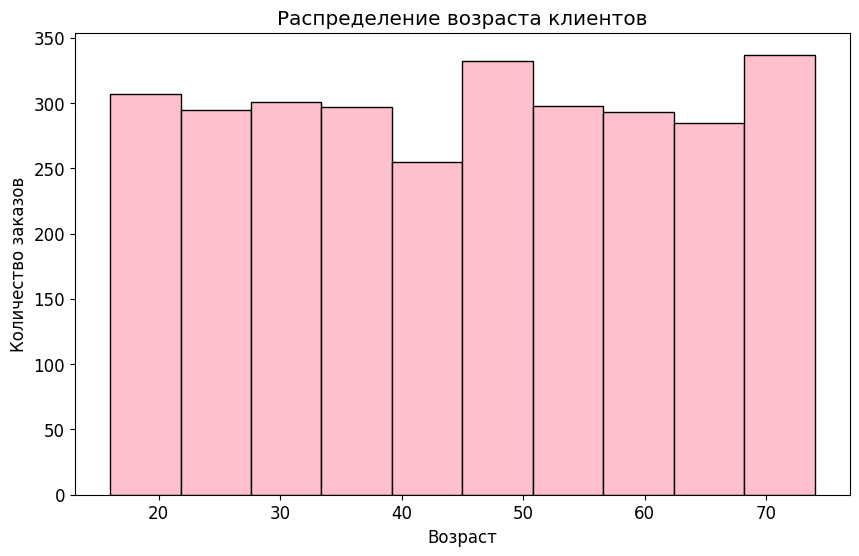

In [43]:
#распредление возраста

plt.hist(df["age"], bins=10, color="pink", edgecolor="black")
plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество заказов")
plt.show()

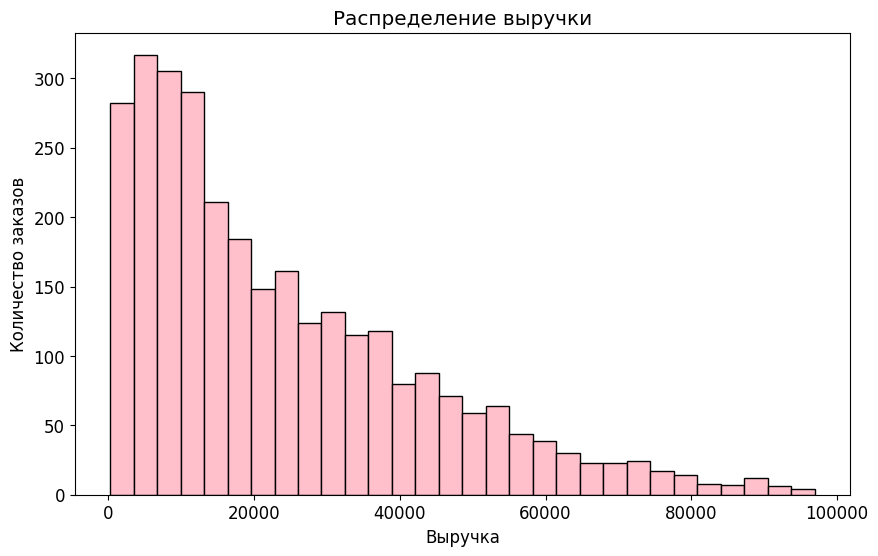

In [44]:
#распределение выручки

plt.hist(df["revenue"], bins=30, color="pink", edgecolor="black")
plt.title("Распределение выручки")
plt.xlabel("Выручка")
plt.ylabel("Количество заказов")
plt.show()

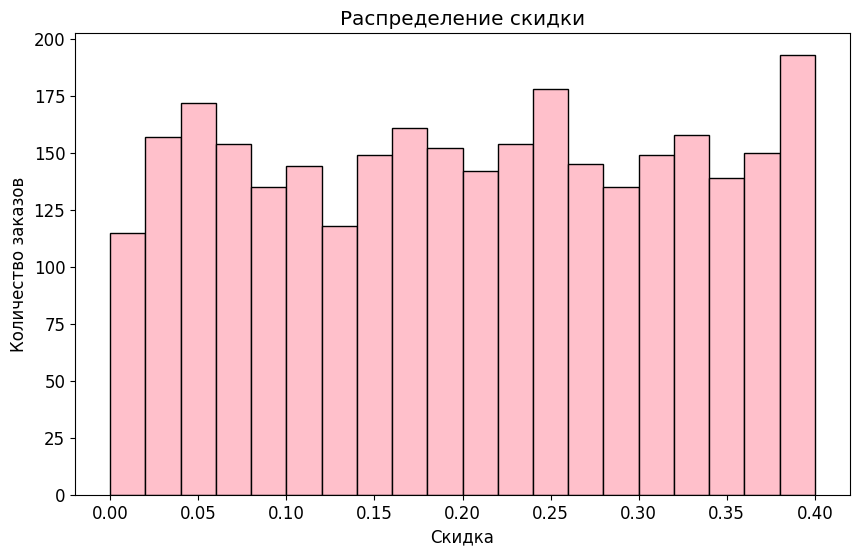

In [45]:
#распр.скидки

plt.hist(df["discount"], bins=20, color="pink", edgecolor="black")
plt.title("Распределение скидки")
plt.xlabel("Скидка")
plt.ylabel("Количество заказов")
plt.show()

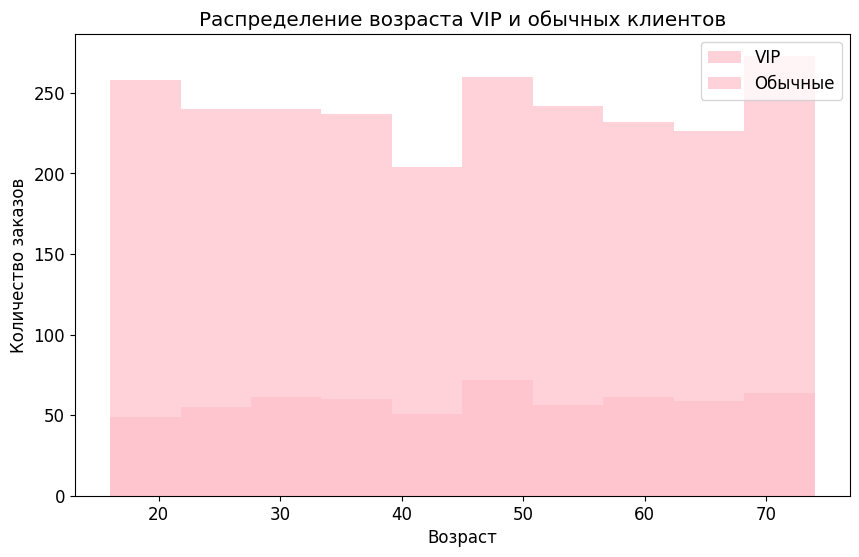

In [46]:
#вип и обычные клиенты

plt.hist(df[df["is_vip"]]["age"], bins=10, alpha=0.7, label="VIP", color="pink")
plt.hist(df[~df["is_vip"]]["age"], bins=10, alpha=0.7, label="Обычные", color="pink")
plt.title("Распределение возраста VIP и обычных клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество заказов")
plt.legend()
plt.show()

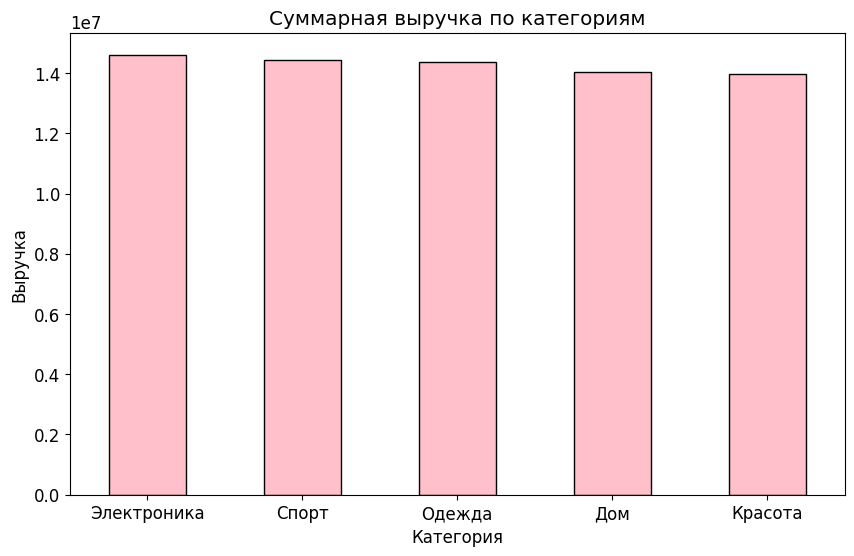

In [47]:
#выручка по категориям

revenue_by_category.plot(kind="bar", color="pink", edgecolor="black")
plt.title("Суммарная выручка по категориям")
plt.xlabel("Категория")
plt.ylabel("Выручка")
plt.xticks(rotation=0)
plt.show()

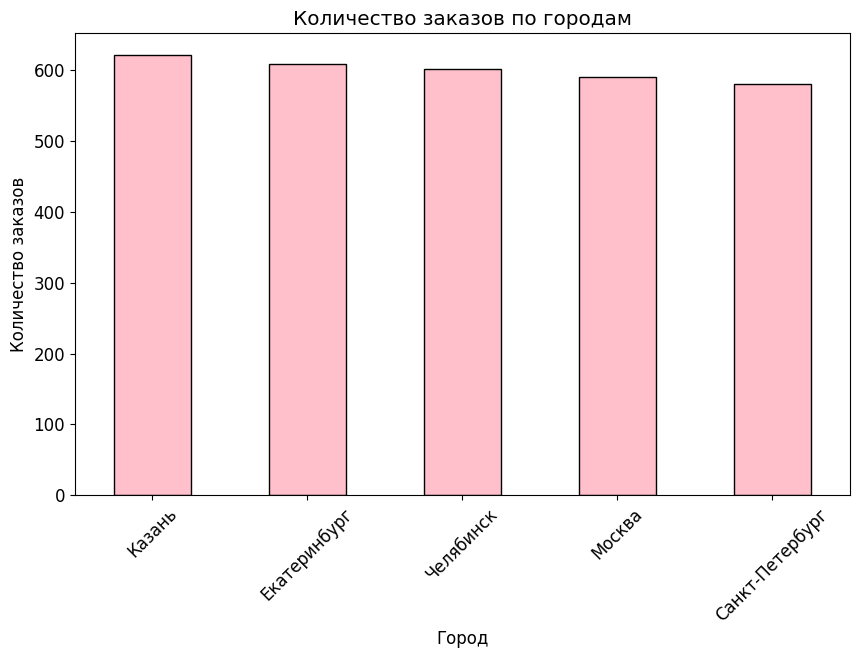

In [48]:
#заказы по городам

orders_by_city = df["city"].value_counts()
orders_by_city.plot(kind="bar", color="pink", edgecolor="black")
plt.title("Количество заказов по городам")
plt.xlabel("Город")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45)
plt.show()

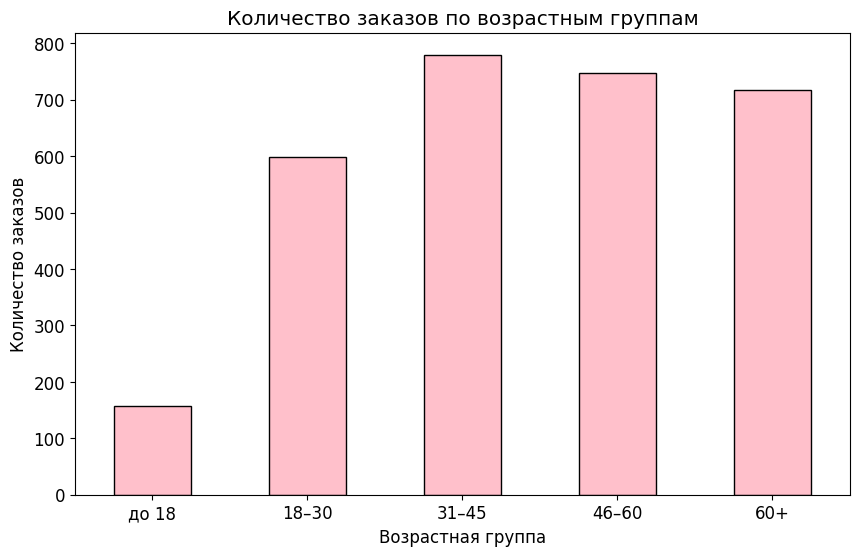

In [49]:
#возрастные группы

age_group_counts = df["age_group"].value_counts().sort_index()
age_group_counts.plot(kind="bar", color="pink", edgecolor="black")
plt.title("Количество заказов по возрастным группам")
plt.xlabel("Возрастная группа")
plt.ylabel("Количество заказов")
plt.xticks(rotation=0)
plt.show()

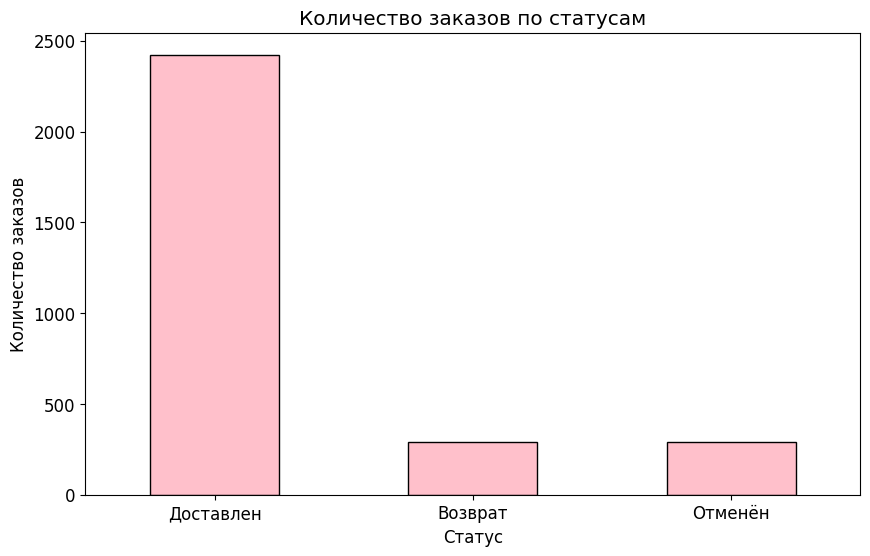

In [50]:
#статусы заказов

status_counts = df["status"].value_counts()
status_counts.plot(kind="bar", color="pink", edgecolor="black")
plt.title("Количество заказов по статусам")
plt.xlabel("Статус")
plt.ylabel("Количество заказов")
plt.xticks(rotation=0)
plt.show()

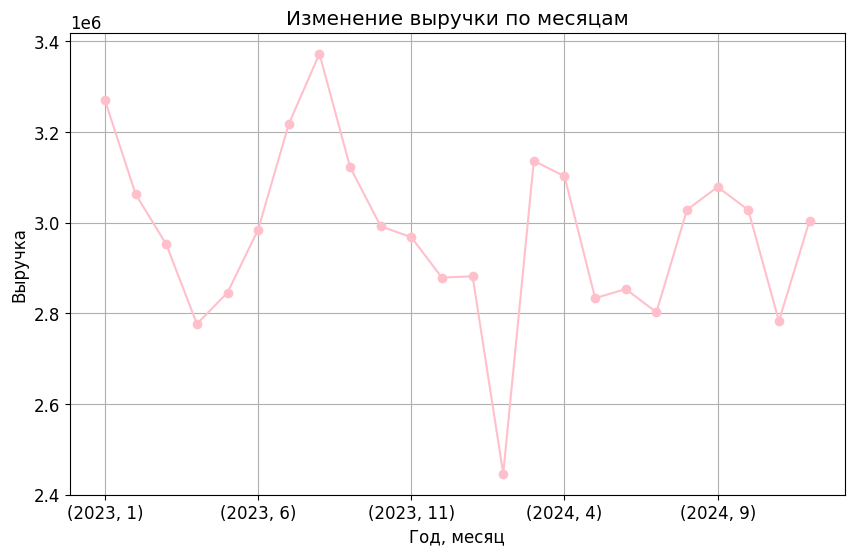

In [51]:
#выручка по месяцам

monthly = df.groupby(["year", "month"])["revenue"].sum()
monthly.plot(kind="line", marker="o", color="pink")
plt.title("Изменение выручки по месяцам")
plt.xlabel("Год, месяц")
plt.ylabel("Выручка")
plt.grid(True)
plt.show()

анализ мини

In [52]:
# Общая статистика
total_orders = len(df)
total_revenue = df["revenue"].sum()
avg_revenue = df["revenue"].mean()

print("Общее количество заказов:", total_orders)
print("Общая выручка:", round(total_revenue, 2))
print("Средняя выручка заказа:", round(avg_revenue, 2))

Общее количество заказов: 3000
Общая выручка: 71422410.11
Средняя выручка заказа: 23807.47


в среднем за заказ магазин получал 23800

In [53]:
# Категории
cat_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(cat_revenue)
print()
print("Максимальная выручка:", cat_revenue.idxmax())
print("Минимальная выручка:", cat_revenue.idxmin())

category
Электроника    14611679.30
Спорт          14446990.09
Одежда         14364620.39
Дом            14041474.19
Красота        13957646.14
Name: revenue, dtype: float64

Максимальная выручка: Электроника
Минимальная выручка: Красота


разница в выручках из-за их цены, электронника приносит больше выручку

In [54]:
# VIP-заказы
vip_revenue = df.loc[df["is_vip"], "revenue"].sum()
total_revenue = df["revenue"].sum()
vip_share = vip_revenue / total_revenue

print("Выручка VIP-заказов:", round(vip_revenue, 2))
print("Общая выручка:", round(total_revenue, 2))
print("Доля VIP-заказов в выручке: {:.2%}".format(vip_share))

Выручка VIP-заказов: 13814094.6
Общая выручка: 71422410.11
Доля VIP-заказов в выручке: 19.34%


выручка от вип заказов досточно большая и составляет большую долю в общем выручке

In [55]:
# Скидки
bins_disc = [0, 0.1, 0.2, 0.3, 0.4]
labels_disc = ["0-10%", "10-20%", "20-30%", "30-40%"]
df["discount_group"] = pd.cut(df["discount"], bins=bins_disc, labels=labels_disc, include_lowest=True)

discount_analysis = df.groupby("discount_group")["revenue"].mean().round(2)
print(discount_analysis)

discount_group
0-10%     28566.84
10-20%    24565.96
20-30%    21730.21
30-40%    19932.21
Name: revenue, dtype: float64


/tmp/ipykernel_792/3943597197.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  discount_analysis = df.groupby("discount_group")["revenue"].mean().round(2)


с ростом скидки выручка снижется т.к. стоимость товара тоже снижается

In [56]:
# Возвраты и отмены
bad_status = df[df["status"].isin(["Отменён", "Возврат"])]

bad_by_category = bad_status.groupby("category")["order_id"].count().sort_values(ascending=False)
print(bad_by_category)

category
Дом            123
Спорт          119
Электроника    114
Красота        112
Одежда         109
Name: order_id, dtype: int64


больше всего отмен в категории дом, а меьше в одежде

Итоговый вывод: В ходе работы выяснилось:
Наибольшую вырочку приносит категория электронника, из-за высокой цены. Среди городов лидирует Казаь на графике. Вип заказы формируют примерно 20 процентов всей выручки, что показывает их значимость. А также выяснилось, что скидки негативно влияют на выручку.